# 04 — Filtrage collaboratif

**Objectif** : recommander des films à partir des seules notes, en exploitant les goûts
d'utilisateurs proches (user-based), la proximité entre films (item-based) et la factorisation
de matrice (ALS), puis comparer ces approches objectivement.

Ce notebook **n'entraîne rien** : il charge les modèles et les résultats produits par
`python scripts/train_collaborative.py`, ce qui garantit que les chiffres affichés ici sont ceux
de l'expérience versionnée dans `reports/collaborative_results.json`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from recsys.analysis import model_report, plots
from recsys.config import load_config
from recsys.experiments.collaborative import (
    ARTIFACT_DIR, PER_USER_FILE, RESULTS_FILE, build_folds, load_ratings,
)
from recsys.models.collaborative import ImplicitALS, ItemKNN, UserKNN

%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 70)

config = load_config()
artifacts = config.paths.artifacts_dir / ARTIFACT_DIR
results = model_report.load_results(config.paths.reports_dir, RESULTS_FILE)
movies = pd.read_parquet(config.paths.processed_dir / "movies.parquet").set_index("movieId")


def show(fig):
    display(fig)
    plt.close(fig)

## 1. Protocole d'évaluation

Séparation **temporelle globale** : on apprend sur le passé, on évalue sur le futur, comme en
production. Aucune note postérieure à la coupure n'entre dans l'entraînement, y compris pour
décider quels films ont assez de notes.

- **validation** : sert à choisir les hyperparamètres ;
- **test** : mesuré une seule fois, avec la configuration retenue, après réentraînement sur
  entraînement + validation.

Sont évalués les utilisateurs ayant un historique avant la coupure et au moins un film aimé
(note ≥ 4) après. Les utilisateurs apparus après la coupure (`holdout_cold_users`) relèvent du
cold start, traité au Sprint 4.

In [2]:
pd.DataFrame(results["folds"]).T

,train_end,holdout_end,train_ratings,train_ratings_dropped_by_movie_filter,train_users,train_items,train_density,holdout_ratings,holdout_users,holdout_cold_users,holdout_positive_share_on_known_items,eval_users,eval_ratings,eval_relevant,eval_median_history
validation,2016-06-25T06:49:57.600000+00:00,2018-01-04T02:45:00.800000+00:00,19905544,94532,137883,13980,0.0103,2500009,18003,12708,0.9351,5006,339963,137353,265.5000
test,2018-01-04T02:45:00.800000+00:00,None,22366789,133296,150591,16007,0.0093,2500010,18442,11950,0.9288,6206,400469,165779,275.0000


## 2. La matrice utilisateur × film

In [3]:
folds = build_folds(load_ratings(config), config)
fold = folds["test"]
matrix = fold.matrix
print(f"{matrix.n_users:,} utilisateurs x {matrix.n_items:,} films, "
      f"{matrix.ratings.nnz:,} notes, densité {matrix.density:.3%}")

popular = np.argsort(-np.diff(matrix.ratings.tocsc().indptr))[:8]
active = np.argsort(-np.diff(matrix.ratings.indptr))[1000:1008]
excerpt = pd.DataFrame(
    matrix.ratings[active][:, popular].toarray(),
    index=[f"utilisateur {u}" for u in matrix.user_ids[active]],
    columns=movies.loc[matrix.item_ids[popular], "title_clean"].str.slice(0, 22),
).replace(0, np.nan)
excerpt.style.format("{:.1f}", na_rep="·")

150,591 utilisateurs x 16,007 films, 22,366,789 notes, densité 0.928%


title_clean,Forrest Gump,"Shawshank Redemption,",Pulp Fiction,"Silence of the Lambs,","Matrix, The",Star Wars: Episode IV,Jurassic Park,Braveheart
utilisateur 94302,4.0,5.0,3.0,4.0,4.0,4.0,4.0,4.0
utilisateur 8979,4.5,5.0,4.5,3.5,5.0,2.5,2.5,·
utilisateur 149412,4.0,5.0,5.0,4.0,5.0,5.0,5.0,5.0
utilisateur 128590,3.5,3.5,4.0,4.0,3.0,3.5,4.0,3.5
utilisateur 117789,5.0,5.0,5.0,5.0,5.0,3.0,2.5,·
utilisateur 119803,3.0,4.0,3.0,5.0,3.0,4.0,4.0,3.0
utilisateur 43091,5.0,5.0,5.0,5.0,5.0,3.0,·,·
utilisateur 18231,4.0,4.0,1.0,4.0,3.0,5.0,3.0,2.0


Même sur les 8 films les plus notés, la matrice a des trous ; sur l'ensemble du catalogue,
plus de 99 % des cases sont vides. Tout l'enjeu est d'estimer ces cases.

## 3. Similarités entre films

**Item-kNN** : deux films sont proches si les mêmes utilisateurs les notent au-dessus (ou en
dessous) de ce que prédisent leurs moyennes. **ALS implicite** : deux films sont proches si
leurs vecteurs latents pointent dans la même direction.

In [4]:
item_knn = ItemKNN.load(artifacts / "item_knn.pkl")
als = ImplicitALS.load(artifacts / "als_implicit.pkl")
titles = movies.loc[item_knn.matrix.item_ids, "title"].to_numpy()


def find(title_part):
    matches = [i for i, t in enumerate(titles) if title_part.lower() in t.lower()]
    if not matches:
        raise KeyError(f"aucun film ne contient {title_part!r}")
    counts = np.diff(item_knn.matrix.ratings.tocsc().indptr)
    return max(matches, key=lambda i: counts[i])


def neighbours_table(title_part, n=8):
    idx = find(title_part)
    knn_items, knn_sims = item_knn.similar_items(idx, n)
    als_items, als_sims = als.similar_items(idx, n)
    print("Film de référence :", titles[idx])
    return pd.DataFrame({
        "Item-kNN": titles[knn_items], "similarité": knn_sims,
        "ALS implicite": titles[als_items], "cosinus": als_sims,
    })


neighbours_table("Matrix, The")

Film de référence : Matrix, The (1999)


,Item-kNN,similarité,ALS implicite,cosinus
0,"Matrix Reloaded, The (2003)",0.1700,"Sixth Sense, The (1999)",0.8124
1,Fight Club (1999),0.1390,Fight Club (1999),0.7980
2,"Lord of the Rings: The Fellowship of the Ring, The (2001)",0.1277,American Beauty (1999),0.7246
3,"Matrix Revolutions, The (2003)",0.1190,Saving Private Ryan (1998),0.6800
4,"Lord of the Rings: The Return of the King, The (2003)",0.1150,Gladiator (2000),0.6378
5,Star Wars: Episode V - The Empire Strikes Back (1980),0.1116,Memento (2000),0.6021
6,"Lord of the Rings: The Two Towers, The (2002)",0.1112,"Shawshank Redemption, The (1994)",0.5644
7,Star Wars: Episode IV - A New Hope (1977),0.1103,Inception (2010),0.5606


In [5]:
neighbours_table("Toy Story (1995)")

Film de référence : Toy Story (1995)


,Item-kNN,similarité,ALS implicite,cosinus
0,Toy Story 2 (1999),0.3106,Toy Story 2 (1999),0.7339
1,"Monsters, Inc. (2001)",0.1853,"Monsters, Inc. (2001)",0.6159
2,Toy Story 3 (2010),0.1744,Aladdin (1992),0.5950
3,Finding Nemo (2003),0.1670,"Bug's Life, A (1998)",0.5867
4,"Bug's Life, A (1998)",0.1593,Finding Nemo (2003),0.5615
5,Aladdin (1992),0.1481,Toy Story 3 (2010),0.5431
6,"Lion King, The (1994)",0.1382,"Lion King, The (1994)",0.5269
7,"Incredibles, The (2004)",0.1354,"Incredibles, The (2004)",0.5196


In [6]:
neighbours_table("Inception")

Film de référence : Inception (2010)


,Item-kNN,similarité,ALS implicite,cosinus
0,Interstellar (2014),0.1770,"Dark Knight, The (2008)",0.8767
1,"Dark Knight, The (2008)",0.1674,"Dark Knight Rises, The (2012)",0.8105
2,Shutter Island (2010),0.1436,Shutter Island (2010),0.7927
3,"Dark Knight Rises, The (2012)",0.1299,Inglourious Basterds (2009),0.7636
4,"Prestige, The (2006)",0.1077,Avatar (2009),0.7543
5,"Matrix, The (1999)",0.0968,WALL·E (2008),0.7523
6,Memento (2000),0.0894,Up (2009),0.7500
7,Batman Begins (2005),0.0858,Django Unchained (2012),0.7120


## 4. Recommandations pour un utilisateur

On prend un utilisateur évalué à l'historique moyen, on regarde ce qu'il a aimé avant la
coupure, puis ce que chaque modèle lui propose. La colonne `aimé ensuite` indique si le film
figure parmi ceux qu'il a réellement notés ≥ 4 après la coupure.

In [7]:
history_size = np.diff(matrix.ratings.indptr)
relevant = fold.relevant.groupby("user_idx")["item_idx"].apply(set)
candidates = [u for u in fold.eval_users if 60 <= history_size[u] <= 150 and len(relevant[u]) >= 8]
user = candidates[0]
row = matrix.ratings[user]
history = pd.DataFrame({"film": titles[row.indices], "note": row.data}).sort_values(
    "note", ascending=False
)
print(f"Utilisateur {matrix.user_ids[user]} : {history_size[user]} notes avant la coupure, "
      f"{len(relevant[user])} films aimés ensuite")
history.head(12).reset_index(drop=True)

Utilisateur 294 : 117 notes avant la coupure, 36 films aimés ensuite


,film,note
0,Taxi Driver (1976),5.0000
1,"Godfather, The (1972)",5.0000
2,"Graduate, The (1967)",5.0000
3,"Shining, The (1980)",5.0000
4,"Decalogue, The (Dekalog) (1989)",5.0000
5,Bad Education (La mala educación) (2004),5.0000
6,Alien (1979),4.5000
7,"Clockwork Orange, A (1971)",4.5000
8,Donnie Darko (2001),4.5000
9,Barry Lyndon (1975),4.5000


In [8]:
genres = movies.loc[matrix.item_ids[row.indices[row.data >= 4]], "genres"].explode()
genres.value_counts().head(6).rename("films aimés").to_frame().T

genres,Drama,Thriller,Crime,Comedy,Mystery,Romance
films aimés,37,17,16,9,8,7


In [9]:
def top10(model, label):
    items, scores = model.recommend(np.array([user]), k=10)
    return pd.DataFrame({
        "modèle": label, "rang": range(1, 11), "film": titles[items[0]], "score": scores[0],
        "aimé ensuite": ["oui" if i in relevant[user] else "" for i in items[0]],
    })


display(top10(item_knn, "Item-kNN"))
display(top10(als, "ALS implicite"))

,modèle,rang,film,score,aimé ensuite
0,Item-kNN,1,Apocalypse Now (1979),0.8099,
1,Item-kNN,2,2001: A Space Odyssey (1968),0.7974,
2,Item-kNN,3,Rosemary's Baby (1968),0.5660,oui
3,Item-kNN,4,Psycho (1960),0.5323,
4,Item-kNN,5,"Exorcist, The (1973)",0.5288,oui
5,Item-kNN,6,Blade Runner (1982),0.4543,
6,Item-kNN,7,Boogie Nights (1997),0.4221,
7,Item-kNN,8,Blue Velvet (1986),0.3942,
8,Item-kNN,9,"Deer Hunter, The (1978)",0.3883,
9,Item-kNN,10,Deliverance (1972),0.3841,


,modèle,rang,film,score,aimé ensuite
0,ALS implicite,1,"Silence of the Lambs, The (1991)",0.9802,
1,ALS implicite,2,Reservoir Dogs (1992),0.9233,
2,ALS implicite,3,2001: A Space Odyssey (1968),0.9095,
3,ALS implicite,4,Apocalypse Now (1979),0.9024,
4,ALS implicite,5,Psycho (1960),0.8722,
5,ALS implicite,6,Requiem for a Dream (2000),0.8136,
6,ALS implicite,7,Seven (a.k.a. Se7en) (1995),0.7973,
7,ALS implicite,8,American History X (1998),0.7798,oui
8,ALS implicite,9,"Usual Suspects, The (1995)",0.7589,
9,ALS implicite,10,Inception (2010),0.7458,


### Pourquoi ce film ?

L'item-kNN est explicable par construction : le score d'un film est la somme des contributions
des films de l'historique qui lui ressemblent.

In [10]:
items, _ = item_knn.recommend(np.array([user]), k=5)
rows = []
for item in items[0]:
    because, contributions = item_knn.explain(user, item, n=3)
    rows.append({
        "film recommandé": titles[item],
        "parce que vous avez aimé": " ; ".join(titles[because]),
        "contributions": np.round(contributions, 3).tolist(),
    })
pd.DataFrame(rows)

,film recommandé,parce que vous avez aimé,contributions
0,Apocalypse Now (1979),"Taxi Driver (1976) ; Shining, The (1980) ; Clockwork Orange, A (1971)","[0.168, 0.146, 0.1]"
1,2001: A Space Odyssey (1968),"Eyes Wide Shut (1999) ; Shining, The (1980) ; Taxi Driver (1976)","[0.158, 0.148, 0.127]"
2,Rosemary's Baby (1968),"Shining, The (1980) ; Eyes Wide Shut (1999) ; Carrie (1976)","[0.119, 0.085, 0.08]"
3,Psycho (1960),"Shining, The (1980) ; Taxi Driver (1976) ; Graduate, The (1967)","[0.168, 0.122, 0.11]"
4,"Exorcist, The (1973)","Shining, The (1980) ; Carrie (1976) ; Fly, The (1986)","[0.152, 0.09, 0.061]"


### User-kNN : qui sont les voisins ?

In [11]:
user_knn = UserKNN.load(artifacts / "user_knn.pkl")
weights = user_knn.neighbours(np.array([user]))
order = np.argsort(-weights.data)[:5]
liked = set(row.indices[row.data >= 4])
rows = []
for neighbour, sim in zip(weights.indices[order], weights.data[order]):
    other = matrix.ratings[neighbour]
    other_liked = set(other.indices[other.data >= 4])
    rows.append({"voisin": matrix.user_ids[neighbour], "similarité": sim,
                 "notes du voisin": other.nnz, "films aimés en commun": len(liked & other_liked)})
display(pd.DataFrame(rows))
display(top10(user_knn, "User-kNN"))
del user_knn

,voisin,similarité,notes du voisin,films aimés en commun
0,822,0.0753,141,13
1,67447,0.0728,69,6
2,94183,0.0699,152,11
3,1281,0.0699,983,12
4,103126,0.0668,1041,26


,modèle,rang,film,score,aimé ensuite
0,User-kNN,1,2001: A Space Odyssey (1968),6.6147,
1,User-kNN,2,Apocalypse Now (1979),4.2547,
2,User-kNN,3,Blue Velvet (1986),3.4227,
3,User-kNN,4,Fargo (1996),2.9567,
4,User-kNN,5,"Big Lebowski, The (1998)",2.8562,oui
5,User-kNN,6,Psycho (1960),2.6264,
6,User-kNN,7,Reservoir Dogs (1992),2.5781,
7,User-kNN,8,Blade Runner (1982),2.4761,
8,User-kNN,9,No Country for Old Men (2007),2.2837,
9,User-kNN,10,Natural Born Killers (1994),2.2821,


## 5. Comparaison des modèles sur le test

In [12]:
test = model_report.results_frame(results["test"])
ks = results["protocol"]["ks"]
for k in ks:
    print(f"Top-{k}")
    display(model_report.ranking_table(test, k).set_index("modèle"))

Top-5


,precision@5,recall@5,f1@5,map@5,ndcg@5,coverage@5
modèle,,,,,,
Popularité,0.0781,0.0207,0.0248,0.0545,0.0861,0.0131
Biais (moyennes),0.0569,0.0199,0.0218,0.0360,0.0605,0.0029
Item-kNN,0.1033,0.0253,0.0319,0.0741,0.1118,0.1794
User-kNN,0.0949,0.0214,0.0278,0.0686,0.1038,0.0853
ALS explicite,0.0334,0.0127,0.0133,0.0209,0.0360,0.1153
ALS implicite,0.1336,0.0345,0.0429,0.0953,0.1446,0.1010


Top-10


,precision@10,recall@10,f1@10,map@10,ndcg@10,coverage@10
modèle,,,,,,
Popularité,0.0654,0.0319,0.0310,0.0406,0.0786,0.0188
Biais (moyennes),0.0463,0.0278,0.0248,0.0264,0.0559,0.0059
Item-kNN,0.0881,0.0414,0.0423,0.0551,0.1029,0.2444
User-kNN,0.0816,0.0363,0.0376,0.0510,0.0953,0.1159
ALS explicite,0.0322,0.0221,0.0183,0.0170,0.0376,0.1706
ALS implicite,0.1202,0.0597,0.0595,0.0747,0.1381,0.1258


Top-20


,precision@20,recall@20,f1@20,map@20,ndcg@20,coverage@20
modèle,,,,,,
Popularité,0.0564,0.0517,0.0383,0.0326,0.0766,0.0272
Biais (moyennes),0.0349,0.0389,0.0261,0.0206,0.0521,0.0099
Item-kNN,0.0738,0.0684,0.0519,0.0434,0.0992,0.3292
User-kNN,0.0684,0.0585,0.0459,0.0397,0.0906,0.1595
ALS explicite,0.0291,0.0357,0.0225,0.0146,0.0400,0.2491
ALS implicite,0.1020,0.0964,0.0727,0.0610,0.1349,0.1531


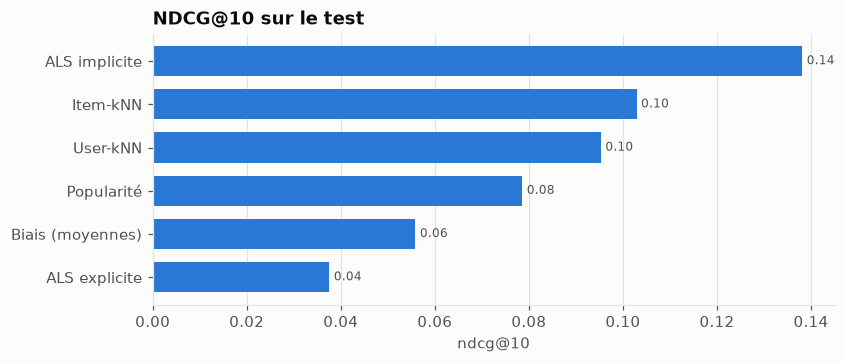

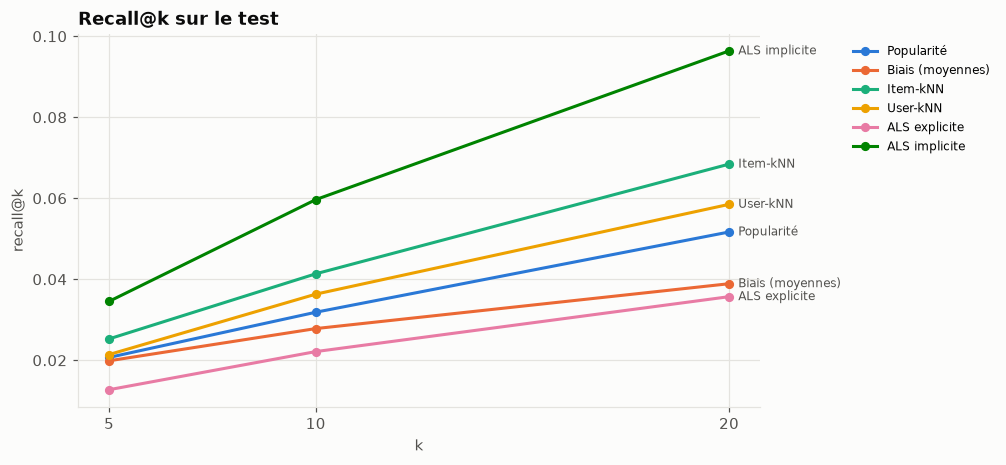

In [13]:
show(model_report.plot_metric(test, "ndcg@10", "NDCG@10 sur le test"))
show(model_report.plot_metric_by_k(test, "recall", ks, "Recall@k sur le test"))

### Prédiction de note

RMSE et MAE ne concernent que les modèles qui prédisent une note. La popularité et l'ALS
implicite produisent un score de préférence, pas une note.

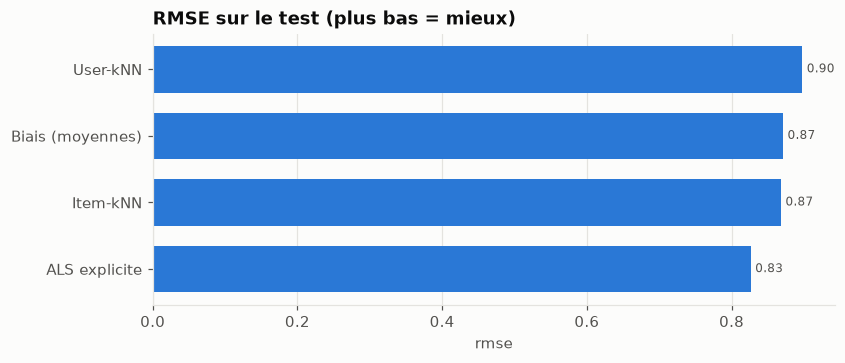

,rmse,mae
modèle,,
Biais (moyennes),0.8710,0.6461
Item-kNN,0.8681,0.6324
User-kNN,0.8976,0.6633
ALS explicite,0.8263,0.6040


In [14]:
show(model_report.plot_metric(test, "rmse", "RMSE sur le test (plus bas = mieux)"))
model_report.rating_table(test).set_index("modèle")

### Couverture, popularité et coût

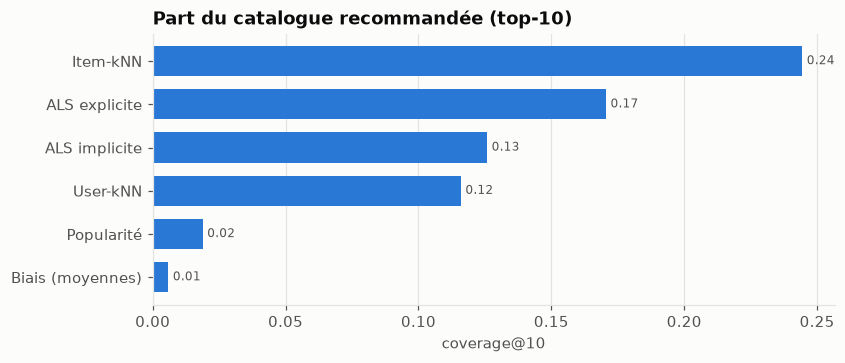

,hyperparamètres retenus,entraînement (s),ms / utilisateur,popularité moyenne du top-10
modèle,,,,
Popularité,relevance_threshold=4.0,0.2,0.3,"49,957"
Biais (moyennes),"reg_item=25, reg_user=10",1.0,0.3,"19,299"
Item-kNN,"k=50, shrinkage=100",92.3,1.7,"12,068"
User-kNN,"k=200, shrinkage=50",4.7,45.0,"19,846"
ALS explicite,"factors=32, reg=0.05, iterations=10",699.5,1.1,"3,421"
ALS implicite,"factors=64, reg=0.01, alpha=10, iterations=15, relevance_threshold=4.0",111.6,0.8,"20,408"


In [15]:
show(model_report.plot_metric(test, "coverage@10", "Part du catalogue recommandée (top-10)"))
model_report.cost_table(test).set_index("modèle").style.format(
    {"entraînement (s)": "{:,.1f}", "ms / utilisateur": "{:,.1f}",
     "popularité moyenne du top-10": "{:,.0f}"}
)

## 6. Analyse d'erreurs

Les modèles réussissent-ils aussi bien pour les petits et les gros historiques ?

In [16]:
per_user = pd.read_parquet(artifacts / PER_USER_FILE)
model_report.segment_table(per_user).set_index("historique")

model,utilisateurs,ALS explicite,ALS implicite,Biais (moyennes),Item-kNN,Popularité,User-kNN
historique,,,,,,,
5-50,703,0.0392,0.1657,0.0595,0.1451,0.1192,0.1206
51-150,1295,0.0264,0.1548,0.0508,0.1189,0.0880,0.1055
151-400,1872,0.0296,0.1357,0.0471,0.0978,0.0658,0.0874
401-1000,1610,0.0441,0.1204,0.0627,0.0826,0.0682,0.0869
> 1000,726,0.0619,0.1270,0.0691,0.0916,0.0786,0.0917


In [17]:
zero = per_user.assign(aucun=per_user["recall@20"] == 0).groupby("model")["aucun"].mean()
zero.rename(index=model_report.MODEL_LABELS).rename(
    "part des utilisateurs sans aucun bon film dans le top-20"
).to_frame().style.format("{:.1%}")

,part des utilisateurs sans aucun bon film dans le top-20
model,
ALS explicite,69.8%
ALS implicite,39.2%
Biais (moyennes),64.9%
Item-kNN,50.4%
Popularité,57.8%
User-kNN,53.3%


## 7. Sélection des hyperparamètres (validation)

In [18]:
validation = model_report.results_frame(results["validation"])
columns = ["label", "params", "ndcg@10", "recall@10", "coverage@10", "rmse", "fit_seconds"]
validation[[c for c in columns if c in validation]].set_index("label")

,params,ndcg@10,recall@10,coverage@10,rmse,fit_seconds
label,,,,,,
Popularité,relevance_threshold=4.0,0.0869,0.0337,0.0195,NaN,0.2035
Biais (moyennes),"reg_item=5, reg_user=5",0.0635,0.0266,0.0068,0.8692,0.8625
Biais (moyennes),"reg_item=25, reg_user=10",0.0597,0.0228,0.0089,0.8680,0.8322
Item-kNN,"k=50, shrinkage=0",0.1150,0.0503,0.3268,0.8679,43.4275
Item-kNN,"k=50, shrinkage=100",0.1198,0.0527,0.2491,0.8602,79.7212
Item-kNN,"k=200, shrinkage=100",0.1187,0.0506,0.2481,0.8325,77.5638
User-kNN,"k=50, shrinkage=0",0.0965,0.0399,0.1904,0.9139,4.3478
User-kNN,"k=200, shrinkage=50",0.1107,0.0439,0.1220,0.8871,4.1454
ALS explicite,"factors=32, reg=0.05, iterations=10",0.0400,0.0218,0.1825,0.8179,423.9797


## 8. Avantages et limites de chaque approche

| Approche | Avantages | Limites |
|---|---|---|
| Popularité | Aucun entraînement, sert de repli pour un nouvel utilisateur | Identique pour tous, couverture minimale |
| Biais | Meilleure base pour la prédiction de note, instantané | Ne personnalise pas le classement : recommande les films les mieux notés |
| Item-kNN | Explicable (« parce que vous avez aimé… »), similarités précalculées, service rapide | Mémoire quadratique sans troncature aux k voisins, sensible aux films peu notés sans amortissement |
| User-kNN | Intuitif, pas de précalcul | Recherche de voisins à chaque requête parmi tous les utilisateurs : le plus coûteux à servir |
| ALS explicite | Meilleure prédiction de note quand les biais sont retirés | Optimise l'erreur sur les notes observées, pas le classement |
| ALS implicite | Optimise directement la préférence, vecteurs compacts réutilisables | Peu explicable, ignore la valeur exacte des notes |

L'interprétation chiffrée de ces résultats figure dans le `README.md`.